29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


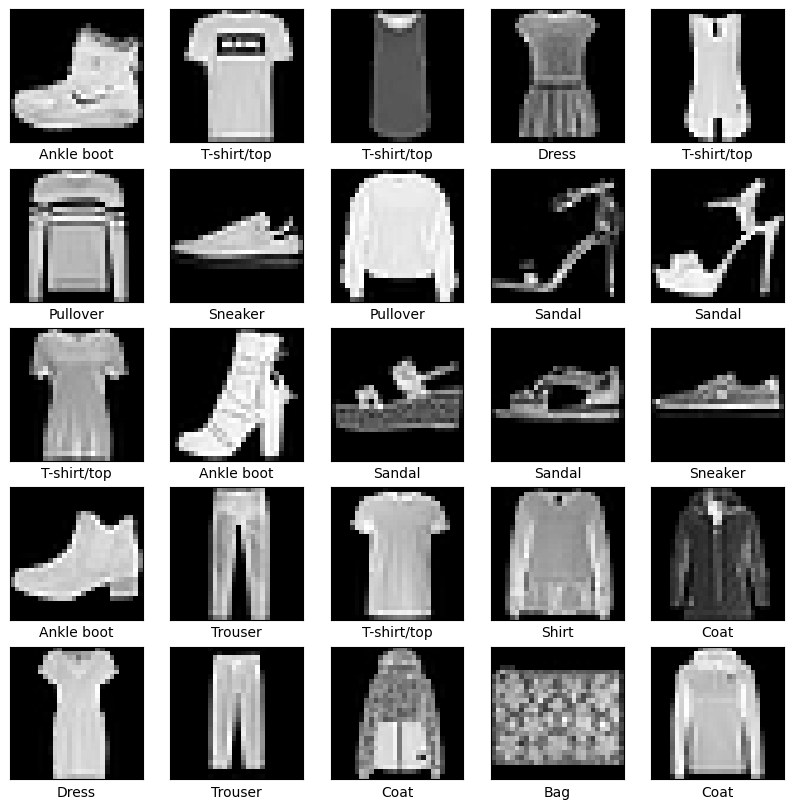

In [1]:
from keras.datasets import fashion_mnist
from keras.utils import to_categorical
from keras import models, layers
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

class_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']

plt.figure(figsize=(10,10))

for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap='gray')
    plt.xlabel(class_names[train_labels[i]])

plt.show()

In [2]:
train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255
train_images = train_images.reshape(-1, 28, 28, 1)
test_images = test_images.reshape(-1, 28, 28, 1)

train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

In [5]:
from keras.layers import Dense, Flatten, Conv2D, MaxPooling2D

network = models.Sequential()
network.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28,28,1)))
network.add(MaxPooling2D(pool_size=(2, 2)))
network.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
network.add(MaxPooling2D(pool_size=(2, 2)))
network.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
network.add(MaxPooling2D(pool_size=(2, 2)))
network.add(Flatten())
network.add(Dense(64, activation='relu'))
network.add(Dense(10, activation='softmax'))

In [6]:
network.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [7]:
network.fit(
    train_images,
    train_labels,
    epochs=25,
    batch_size=128
)

Epoch 1/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.7496 - loss: 0.6936
Epoch 2/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.8341 - loss: 0.4540
Epoch 3/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - accuracy: 0.8580 - loss: 0.3880
Epoch 4/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8698 - loss: 0.3516
Epoch 5/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8811 - loss: 0.3239
Epoch 6/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.8895 - loss: 0.2995
Epoch 7/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 25ms/step - accuracy: 0.8961 - loss: 0.2811
Epoch 8/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.9018 - loss: 0.2655
Epoch 9/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 24ms/step - accuracy: 0.9069 - loss: 0.2507
Epoch 10/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 13s 27ms/step - accuracy: 0.9129 - loss: 0.2331
Epoch 11/25
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 26ms/step - accuracy: 0.9173 - loss: 0.2237
Epoch 12/25
469/469 ━━━━━━━━━━

In [8]:
test_loss, test_acc = network.evaluate(
    test_images,
    test_labels
)
network.save('model-FNMIST.keras')

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8930 - loss: 0.3871


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


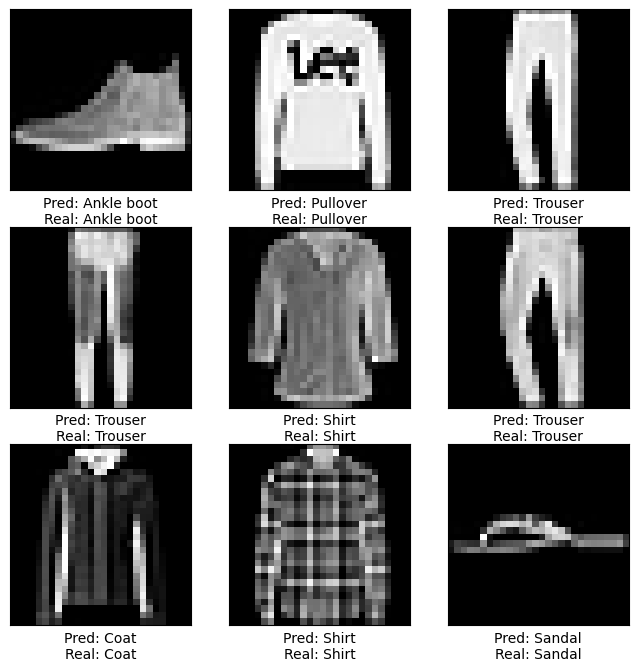

In [11]:
import numpy as np

predictions = network.predict(test_images)
plt.figure(figsize=(8,8))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(test_images[i].reshape(28,28), cmap='gray')
    predicted_label = np.argmax(predictions[i])
    true_label = np.argmax(test_labels[i])

    plt.xlabel(
        "Pred: " + class_names[predicted_label] +
        "\nReal: " + class_names[true_label]
    )

    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

plt.show()